# Week4
專案結構：`main.ipynb`、`Codes/Quiz1.py ~ Quiz4.py`、`Data/`、`Outputs/`
- 圖片輸出：`Outputs/Q{n}_*.png`
- 模型輸出：`Outputs/q{n}_*.pt`

**Colab執行前**：把 `ROOT` 改成 Google Drive 的專案資料夾，並把 `Quiz1.py ~ Quiz4.py` 放進 `ROOT/Codes/`。

In [14]:
'''from google.colab import drive
drive.mount('/content/drive')

# 修改成你的專案資料夾
#ROOT = '/content/drive/MyDrive/Quizzes
ROOT = Path.cwd()''' 

"from google.colab import drive\ndrive.mount('/content/drive')\n\n# 修改成你的專案資料夾\n#ROOT = '/content/drive/MyDrive/Quizzes\nROOT = Path.cwd()"

In [1]:
import sys
import os
from pathlib import Path

import numpy as np
import pandas as pd
import torch

# Notebook 的目前工作目錄，例如 ~/class/MMIP/week4
PROJECT_ROOT = Path.cwd()
CODE_DIR = PROJECT_ROOT / "Codes"

# 加入 Python 模組搜尋路徑
sys.path.insert(0, str(CODE_DIR))

import Quiz1 as q1
import Quiz2 as q2
import Quiz3 as q3
import Quiz4 as q4

# 資料集根目錄：依 q1.get_paths() 的實際需求調整
ROOT = str(PROJECT_ROOT)

paths = q1.get_paths(ROOT)
q1.set_seed(42)

print("Project root:", PROJECT_ROOT)
print("Code directory:", CODE_DIR)
print("device:", "cuda" if torch.cuda.is_available() else "cpu")

print('device:', 'cuda' if torch.cuda.is_available() else 'cpu')

Project root: /cluster/home/m315832001/class/MMIP/week4
Code directory: /cluster/home/m315832001/class/MMIP/week4/Codes
device: cuda
device: cuda


## Quiz 1：資料集準備

### 1-1 Sentiment Analysis dataset: Yelp Review Full

Yelp(3-class) train=90000, test=30000
count    90000.0
mean       136.0
std        121.2
min          1.0
25%         54.0
50%        101.0
75%        178.0
max       1013.0


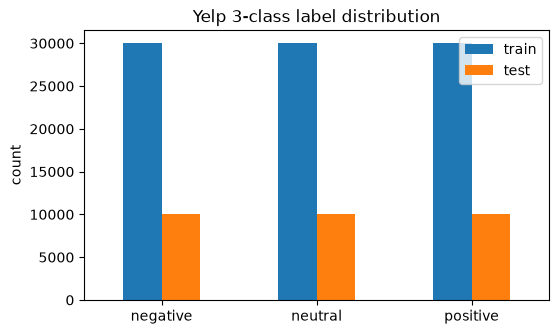

[saved] /cluster/home/m315832001/class/MMIP/week4/Outputs/Q1_yelp_label_dist.png


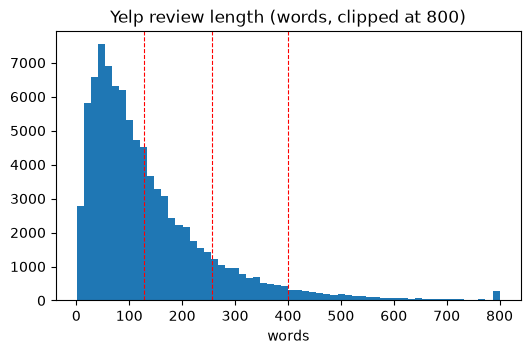

[saved] /cluster/home/m315832001/class/MMIP/week4/Outputs/Q1_yelp_length_hist.png


In [16]:
yelp_train, yelp_test = q1.prepare_yelp(paths, n_per_class_train=30000, n_per_class_test=10000)

### 1-2 Image Classification dataset:　CUB-200-2011

/cluster/home/m315832001/miniconda3/envs/mmip_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 1.49G/1.49G [01:10<00:00, 22.7MB/s]

Extracting files...


  loaded 2000/11788
  loaded 4000/11788
  loaded 6000/11788
  loaded 8000/11788
  loaded 10000/11788
{'x_train': (5994, 256, 256, 3), 'y_train': (5994,), 'x_test': (5794, 256, 256, 3), 'y_test': (5794,)} classes=200 split=official


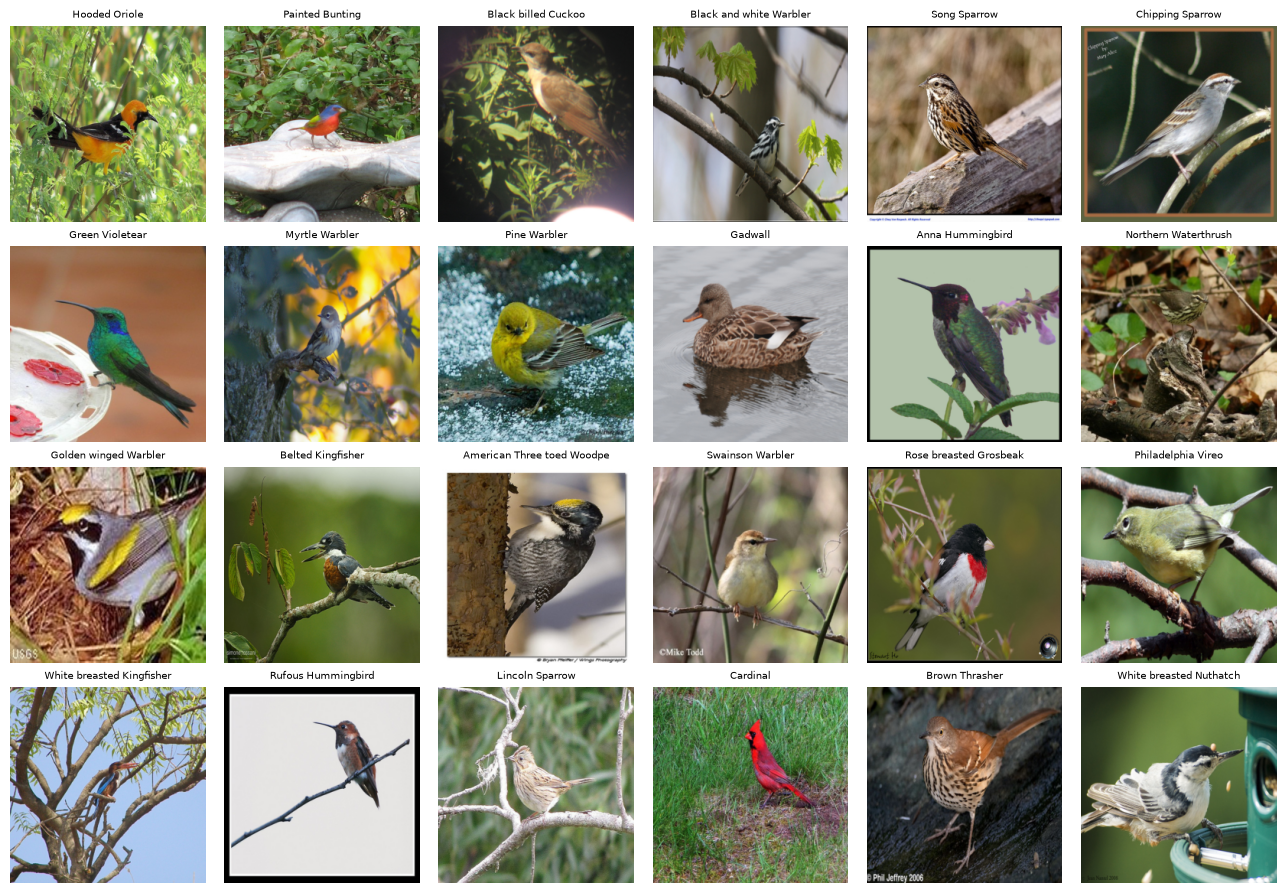

[saved] /cluster/home/m315832001/class/MMIP/week4/Outputs/Q1_cub_samples.png


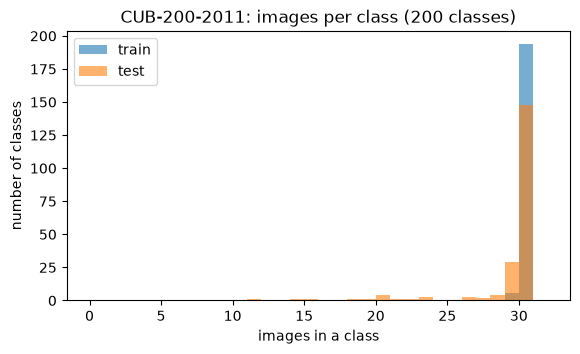

[saved] /cluster/home/m315832001/class/MMIP/week4/Outputs/Q1_cub_label_dist.png


In [2]:
# 若匿名下載失敗：於 Kaggle 建立 API token，並設定 KAGGLE_USERNAME / KAGGLE_KEY 環境變數
cub = q1.prepare_cub(paths, size=256)

### 1-3 Image Captioning datasets: Flickr8k

{'train': 6000, 'val': 1000, 'test': 1000}


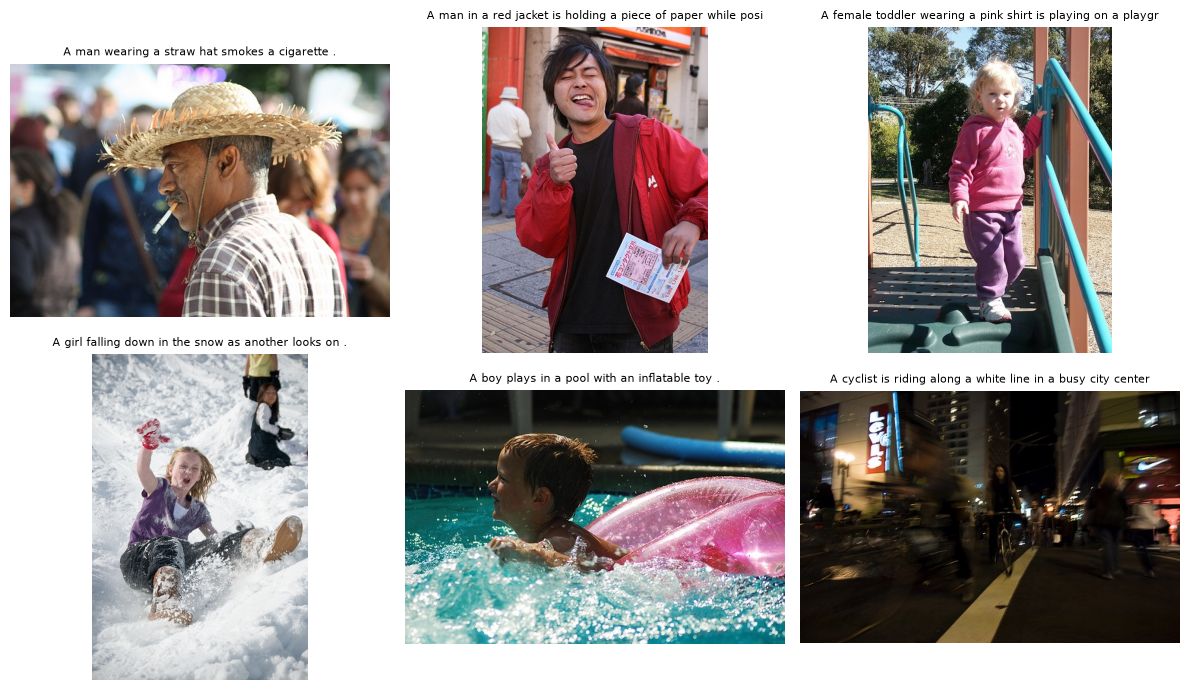

[saved] /cluster/home/m315832001/class/MMIP/week4/Outputs/Q1_flickr8k_samples.png


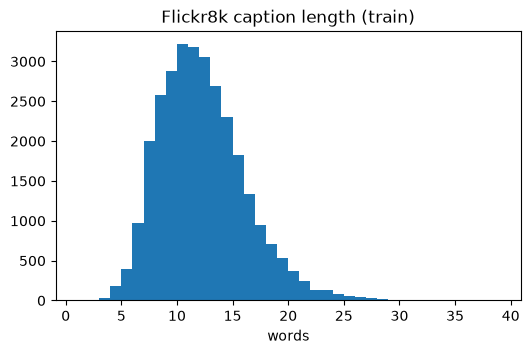

[saved] /cluster/home/m315832001/class/MMIP/week4/Outputs/Q1_flickr8k_caption_length.png


In [2]:
# 第一次執行會把 8000 張圖寫進 Drive，需數分鐘
flickr = q1.prepare_flickr8k(paths)

### Quiz 1 資料集摘要
| 任務 | 資料集 | 使用方式 | 規模 |
|---|---|---|---|
| Sentiment Analysis | Yelp Review Full（HuggingFace） | 1–2 星=negative、3 星=neutral、4–5 星=positive，三類數量相同 | 訓練 90,000（每類 30,000）、測試 30,000（每類 10,000）；平均 136 字、中位數 101 字 |
| Image Classification | CUB-200-2011（Kaggle `wenewone/cub2002011`） | 200 種鳥類的細粒度分類；沿用官方切分，官方訓練集再切 90/10 為 train/val，官方測試集為測試 | 官方約 5,994 張訓練、5,794 張測試（實際張數以執行輸出為準）；影像 resize 為 256×256，訓練時隨機裁切 224、驗證/測試中心裁切 224 |
| Image Captioning | Flickr8k（HuggingFace `jxie/flickr8k`） | 沿用官方切分，每張圖 5 句描述 | train 6,000、val 1,000、test 1,000 |

## Quiz 2：Sentiment Analysis（Yelp - 3 class）
**任務**：判斷評論為 negative / neutral / positive。

**前處理**：移除跳行與跳脫字元 → 小寫並以正規表示式分詞 → 以訓練集建詞表（20,000 詞，含 `<PAD>`、`<UNK>`）→ 轉成 ID → 截斷或補齊至 256 → Embedding。訓練資料再切 90/10（分層）為 train/val（81,000 / 9,000）。

**模型設定（RNN 與 LSTM 完全相同，只換循環單元）**
| 項目 | 設定 |
|---|---|
| 結構 | Embedding(128) → 單層、單向 RNN 或 LSTM（hidden 128）→ Dropout(0.3) → Linear(3) |
| 序列處理 | `pack_padded_sequence`，取最後一個「真實」詞的隱藏狀態，避免 PAD 影響 |
| 最大序列長度 | 256 |
| 損失 / 優化器 | CrossEntropy / Adam，lr = 1e-3，batch size = 128，梯度裁剪 1.0 |
| Early stopping | 監控 val loss，連續 5 個 epoch 沒進步就停止，並還原最佳權重（上限 30 epochs） |
| 參數量 | RNN 2,593,411；LSTM 2,692,483（LSTM 僅多約 3.8%） |
| 評估指標 | Accuracy、Macro-F1、Macro-AUC（OvR）、嚴重錯誤率（negative↔positive 互判）、混淆矩陣 |

In [ ]:
ctx2 = q2.prepare_data(paths, yelp_train, yelp_test, vocab_size=20000)
MAX_LEN = 256

train=81000 val=9000 test=30000 vocab=20000


### 2-1 RNN

In [ ]:
rnn_res = q2.run_experiment(ctx2, 'rnn', MAX_LEN, max_epochs=30, patience=5)
q2.save_model(ctx2, rnn_res[0], 'rnn', MAX_LEN)

[rnn L=256] ep1 tr_loss=1.0295 tr_acc=0.4642 va_loss=1.0139 va_acc=0.4922
[rnn L=256] ep2 tr_loss=0.9409 tr_acc=0.5438 va_loss=0.9507 va_acc=0.5497
[rnn L=256] ep3 tr_loss=0.9053 tr_acc=0.5756 va_loss=1.0055 va_acc=0.5144
[rnn L=256] ep4 tr_loss=0.8761 tr_acc=0.5918 va_loss=0.9439 va_acc=0.5560
[rnn L=256] ep5 tr_loss=0.8619 tr_acc=0.6008 va_loss=0.8520 va_acc=0.6258
[rnn L=256] ep6 tr_loss=0.8390 tr_acc=0.6160 va_loss=0.8422 va_acc=0.5914
[rnn L=256] ep7 tr_loss=0.8238 tr_acc=0.6262 va_loss=0.8076 va_acc=0.6398
[rnn L=256] ep8 tr_loss=0.8110 tr_acc=0.6338 va_loss=0.8927 va_acc=0.6139
[rnn L=256] ep9 tr_loss=0.7976 tr_acc=0.6401 va_loss=0.8119 va_acc=0.6184
[rnn L=256] ep10 tr_loss=0.7824 tr_acc=0.6502 va_loss=0.8382 va_acc=0.6237
[rnn L=256] ep11 tr_loss=0.7798 tr_acc=0.6500 va_loss=0.7690 va_acc=0.6627
[rnn L=256] ep12 tr_loss=0.7678 tr_acc=0.6552 va_loss=0.8271 va_acc=0.6349
[rnn L=256] ep13 tr_loss=0.7508 tr_acc=0.6662 va_loss=0.7620 va_acc=0.6648
[rnn L=256] ep14 tr_loss=0.7552 tr

### 2-2 LSTM

In [ ]:
lstm_res = q2.run_experiment(ctx2, 'lstm', MAX_LEN, max_epochs=30, patience=5)
q2.save_model(ctx2, lstm_res[0], 'lstm', MAX_LEN)

[lstm L=256] ep1 tr_loss=0.9035 tr_acc=0.5601 va_loss=0.8069 va_acc=0.6487
[lstm L=256] ep2 tr_loss=0.7461 tr_acc=0.6665 va_loss=0.7594 va_acc=0.6770
[lstm L=256] ep3 tr_loss=0.6793 tr_acc=0.6986 va_loss=0.7337 va_acc=0.6990
[lstm L=256] ep4 tr_loss=0.6321 tr_acc=0.7233 va_loss=0.7182 va_acc=0.7130
[lstm L=256] ep5 tr_loss=0.5971 tr_acc=0.7402 va_loss=0.6248 va_acc=0.7279
[lstm L=256] ep6 tr_loss=0.5707 tr_acc=0.7533 va_loss=0.6279 va_acc=0.7393
[lstm L=256] ep7 tr_loss=0.5453 tr_acc=0.7662 va_loss=0.6047 va_acc=0.7433
[lstm L=256] ep8 tr_loss=0.5278 tr_acc=0.7734 va_loss=0.6228 va_acc=0.7437
[lstm L=256] ep9 tr_loss=0.5069 tr_acc=0.7838 va_loss=0.6095 va_acc=0.7473
[lstm L=256] ep10 tr_loss=0.4917 tr_acc=0.7924 va_loss=0.6054 va_acc=0.7493
[lstm L=256] ep11 tr_loss=0.4719 tr_acc=0.8008 va_loss=0.6457 va_acc=0.7424
[lstm L=256] ep12 tr_loss=0.4569 tr_acc=0.8076 va_loss=0.6141 va_acc=0.7456
[lstm] early stop at epoch 12 (best epoch 7)
[saved] /cluster/home/m315832001/class/MMIP/week4/Ou

### 2-3 測試集推論與分類結果

In [ ]:
rnn_model, _, rnn_p, test_y, _ = rnn_res
lstm_model, _, lstm_p, _, _ = lstm_res
pred_df = q2.save_test_predictions(ctx2, test_y, rnn_p, lstm_p)
pred_df.sample(10, random_state=1)

[saved] /cluster/home/m315832001/class/MMIP/week4/Outputs/q2_test_predictions.csv


,text,true,rnn_pred,rnn_conf,lstm_pred,lstm_conf
10747,I come from socal and this place would never s...,negative,neutral,0.642153,neutral,0.796641
12573,The good news is: The food at The Orange Table...,neutral,negative,0.657173,neutral,0.570478
29676,I was very disappointed with my recent service...,negative,negative,0.902984,negative,0.997498
8856,You can either pay $5.50 for 3-day movie renta...,neutral,negative,0.799431,negative,0.718545
21098,Horrible service. Went for a polish change on ...,negative,neutral,0.471833,negative,0.986065
17458,I tried Cafe Lalibela (and Ethiopian food) for...,positive,positive,0.857496,positive,0.988925
1476,love the small space and the food is good too....,neutral,neutral,0.602178,neutral,0.601646
5120,Have visited twice. Second time was better tha...,neutral,neutral,0.518964,neutral,0.848099
18338,"Tapas great, paella salty. Never had it before...",neutral,neutral,0.540167,neutral,0.880541
28279,The Orleans Showroom is a nice venue where nea...,negative,negative,0.834261,neutral,0.834109


In [ ]:
# 分類結果
demo = ["Absolutely amazing food and the staff were so friendly. Will definitely come back!",
        "Terrible service, cold food, and we waited over an hour. Never again.",
        "It was okay. Nothing special, but nothing wrong either."]
pr, pl = q2.predict_texts(ctx2, rnn_model, demo, MAX_LEN), q2.predict_texts(ctx2, lstm_model, demo, MAX_LEN)
print(pd.DataFrame({'text': [d[:50] for d in demo],
                    'RNN': [q2.CLASS_NAMES[i] for i in pr.argmax(1)],
                    'LSTM': [q2.CLASS_NAMES[i] for i in pl.argmax(1)]}).to_string())

                                                 text       RNN      LSTM
0  Absolutely amazing food and the staff were so frie  positive  positive
1  Terrible service, cold food, and we waited over an  negative  negative
2  It was okay. Nothing special, but nothing wrong ei   neutral   neutral


### 2-4 RNN vs LSTM 評估比較
（Accuracy / Macro-F1 / Macro-AUC / 嚴重錯誤率）

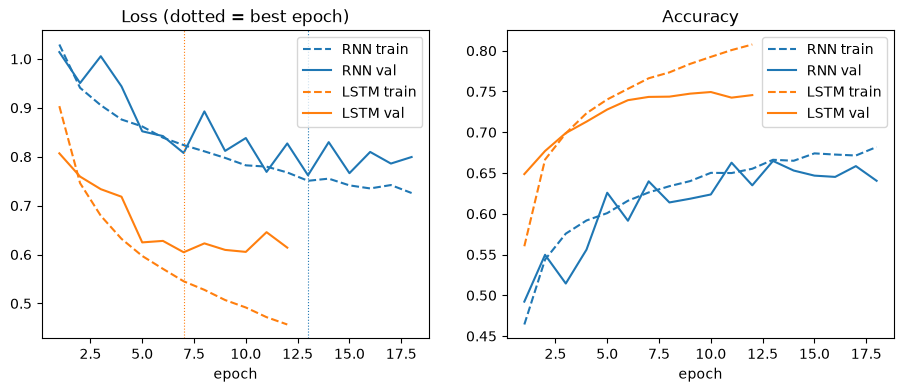

[saved] /cluster/home/m315832001/class/MMIP/week4/Outputs/Q2_training_curves.png


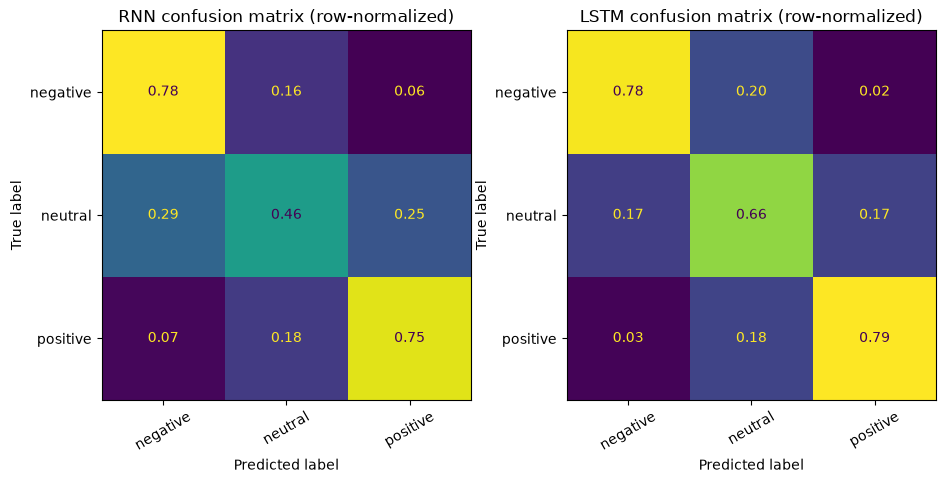

[saved] /cluster/home/m315832001/class/MMIP/week4/Outputs/Q2_confusion_matrix.png


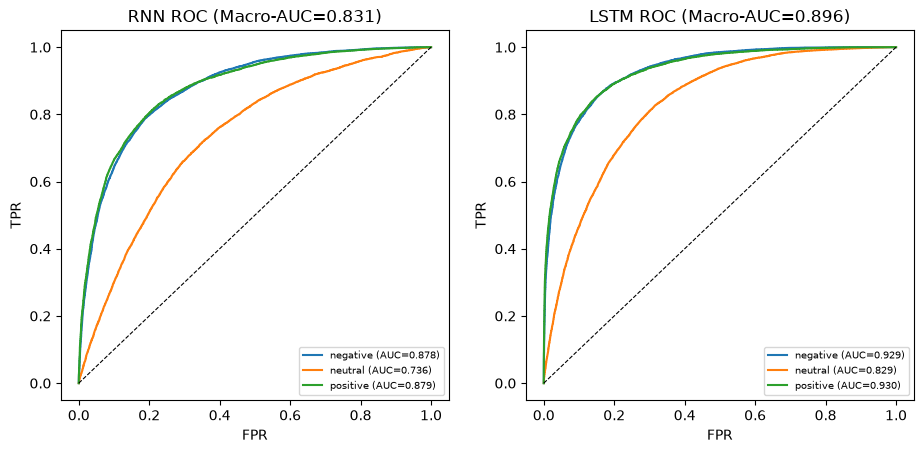

[saved] /cluster/home/m315832001/class/MMIP/week4/Outputs/Q2_roc_curve.png


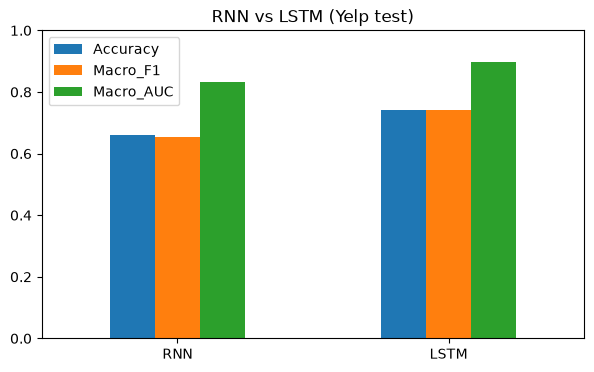

[saved] /cluster/home/m315832001/class/MMIP/week4/Outputs/Q2_metrics_bar.png


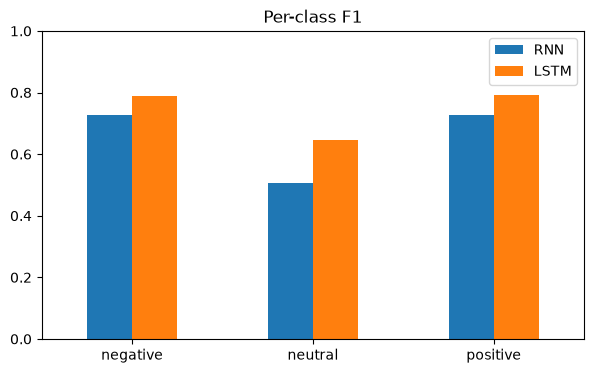

[saved] /cluster/home/m315832001/class/MMIP/week4/Outputs/Q2_per_class_f1.png


,Accuracy,Macro_F1,Macro_AUC,Severe_error,Params,Epochs_run,Best_epoch,Train_time_s
RNN,0.6607,0.6535,0.8309,0.0428,2593411,18,13,94.0728
LSTM,0.7414,0.7423,0.8958,0.0185,2692483,12,7,74.3709


In [ ]:
metrics2 = q2.compare(ctx2, rnn_res, lstm_res)
display(metrics2.round(4))

#### 2-4 結果分析（測試集 30,000 筆）
| 模型 | Accuracy | Macro-F1 | Macro-AUC | 嚴重錯誤率 | 最佳 / 實際 epoch | 訓練時間 |
|---|---|---|---|---|---|---|
| RNN | 0.6607 | 0.6535 | 0.8309 | 4.28% | 13 / 18 | 94 s |
| LSTM | **0.7414** | **0.7423** | **0.8958** | **1.85%** | 7 / 12 | 74 s |

- **LSTM 全面較佳**：Accuracy 高 8.1 %，Macro-F1 高 8.9 %，Macro-AUC 高 0.065，且嚴重錯誤率不到 RNN 的一半。兩者參數量接近，差異主要來自循環單元的結構，而不是模型大小。
- **各類別**（見混淆矩陣）：negative 兩者 recall 皆為 0.78；positive 為 0.75（RNN）與 0.79（LSTM）。**差距主要在 neutral**：RNN 只有 0.46，LSTM 為 0.66。中立評論語意最模糊，RNN 常把它誤判成 negative（0.29）或 positive（0.25）。
- **訓練穩定性**：RNN 的 val loss 起伏很大（例如第 3 個 epoch 回升到 1.0055，第 8 個 epoch 又回升到 0.8927），要到第 13 個 epoch 才達到最佳；LSTM 在第 7 個 epoch 就達到最佳且曲線平滑，所以訓練時間反而較短。
- **過擬合**：LSTM 最佳點之後 train accuracy 持續上升（約 0.80）而 val accuracy 持平，early stopping 在此發揮作用。

### 2-5 extra：不同序列長度對照實驗
每個長度各訓練 RNN 與 LSTM 一次，early stopping 設為 patience = 2、上限 15 epochs（比主實驗嚴格，所以 L=256 的 RNN 數字與 2-4 略有不同）。

{'model': 'RNN', 'max_len': 64, 'Accuracy': 0.5902666666666667, 'Macro_F1': 0.5856411680586028, 'Macro_AUC': 0.7648870666666666, 'best_epoch': 8, 'train_time_s': 19.441131591796875}
{'model': 'LSTM', 'max_len': 64, 'Accuracy': 0.6780666666666667, 'Macro_F1': 0.6777819581337363, 'Macro_AUC': 0.8521592958333333, 'best_epoch': 6, 'train_time_s': 17.685758352279663}
{'model': 'RNN', 'max_len': 128, 'Accuracy': 0.6013333333333334, 'Macro_F1': 0.5931296850944773, 'Macro_AUC': 0.7689592766666666, 'best_epoch': 5, 'train_time_s': 22.251630783081055}
{'model': 'LSTM', 'max_len': 128, 'Accuracy': 0.7277333333333333, 'Macro_F1': 0.7284130201900799, 'Macro_AUC': 0.8860019916666667, 'best_epoch': 9, 'train_time_s': 39.54838752746582}
{'model': 'RNN', 'max_len': 256, 'Accuracy': 0.6397, 'Macro_F1': 0.6434755963847067, 'Macro_AUC': 0.810027215, 'best_epoch': 7, 'train_time_s': 47.23612022399902}
{'model': 'LSTM', 'max_len': 256, 'Accuracy': 0.7413666666666666, 'Macro_F1': 0.742313005055118, 'Macro_AU

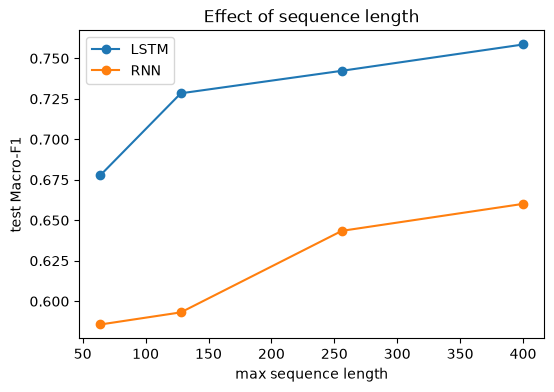

[saved] /cluster/home/m315832001/class/MMIP/week4/Outputs/Q2_length_experiment.png


,model,max_len,Accuracy,Macro_F1,Macro_AUC,best_epoch,train_time_s
0,RNN,64,0.5903,0.5856,0.7649,8,19.4411
1,LSTM,64,0.6781,0.6778,0.8522,6,17.6858
2,RNN,128,0.6013,0.5931,0.7690,5,22.2516
3,LSTM,128,0.7277,0.7284,0.8860,9,39.5484
4,RNN,256,0.6397,0.6435,0.8100,7,47.2361
5,LSTM,256,0.7414,0.7423,0.8958,7,55.7502
6,RNN,400,0.6657,0.6601,0.8387,12,96.9692
7,LSTM,400,0.7583,0.7586,0.9068,9,92.7744


In [ ]:
RUN_LENGTH_EXP = True
if RUN_LENGTH_EXP:
    len_df = q2.length_experiment(ctx2, lengths=(64, 128, 256, 400), max_epochs=15, patience=2)
    display(len_df.round(4))

#### 2-5 結果分析
| 長度 | RNN Acc | LSTM Acc | 差距 | RNN Macro-F1 | LSTM Macro-F1 |
|---|---|---|---|---|---|
| 64 | 0.590 | 0.678 | +8.8 | 0.586 | 0.678 |
| 128 | 0.601 | 0.728 | +12.6 | 0.593 | 0.728 |
| 256 | 0.640 | 0.741 | +10.2 | 0.643 | 0.742 |
| 400 | 0.666 | 0.758 | +9.3 | 0.660 | 0.759 |

- **兩個模型都隨序列變長而進步**（RNN 0.590 → 0.666，LSTM 0.678 → 0.758）。Yelp 評論中位數 101 字、75% 分位數 178 字，長度 64 會截掉大量內容，長度 400 則幾乎涵蓋整篇，所以資訊量增加的效益大於長序列對 RNN 的傷害。
- **LSTM 在每個長度都明顯領先 RNN**（8.8–12.6 %），但差距並不隨長度單調擴大，最大差距出現在 128。因此本實驗**不能**證實「序列越長，RNN 退化越嚴重」，只能說「LSTM 在所有測試長度都更好」。

## Quiz 3：Vision Transformer（CUB-200-2011, 200 class）
兩個模型都使用 ImageNet 預訓練權重，**完整微調**（不凍結），並用相同的資料、增強、優化器、early stopping 設定，只換模型與學習率，確保比較公平。CUB 是細粒度分類（類別之間外觀很接近），每類只有約 30 張訓練圖，比一般場景分類難得多。

| 項目 | ViT | ResNet |
|---|---|---|
| 模型 | torchvision `vit_b_16`（`IMAGENET1K_V1`），分類頭換成 Linear(768→200) | torchvision `resnet50`（`IMAGENET1K_V2`），`fc` 換成 Linear(2048→200) |
| 參數量 | 約 86.0 M | 約 23.9 M |
| 骨幹 / 分類頭學習率 | 3e-5 / 3e-4 | 1e-4 / 1e-3 |
| 優化器 | AdamW（weight decay 0.05） | AdamW（weight decay 0.05） |

- 分類頭學習率為骨幹的 10 倍（`head_lr_mult=10`）：200 類的新分類頭從隨機初始化學起，需要比骨幹更快的更新。兩個模型使用相同倍率。
- 學習率排程: ReduceLROnPlateau（val loss 停滯 1 個 epoch 即 ×0.3）
- 精度 / batch: 混合精度 fp16 / 64
- 訓練增強: RandomResizedCrop(224, scale 0.5–1.0)、水平翻轉、ImageNet 正規化
- 驗證/測試前處理: CenterCrop(224)（影像先 resize 為 256×256）+ ImageNet 正規化
- Early stopping: val loss, patience = 5，最多 30 epochs，並還原最佳權重
- 驗證集每類只有約 3 張，val 的 Macro-AUC 與 accuracy 波動大，只作為訓練中的參考；最終比較以測試集為準
- 評估指標: Top-1 accuracy、**Top-5 accuracy**、Macro-F1、**Macro-AUC（OvR，200 類平均）**、每類別 AUC 與 accuracy、巨觀平均 ROC、錯誤熱圖、最難的 15 個類別
- 200 類無法逐類畫 ROC 與標示混淆矩陣，所以改用巨觀平均 ROC、去除對角線的錯誤熱圖，以及最常被混淆的類別對（`q3_top_confusions.csv`）

In [3]:
ctx3 = q3.build_context(paths, cub, bs=64)

train=5394 val=600 test=5794 classes=200


### 3-1 微調 ViT-B/16

In [4]:
vit_res = q3.train(ctx3, 'vit', max_epochs=30, patience=5, lr=3e-5, head_lr_mult=10)

[vit] ep1 loss=4.0004 val_loss=2.6512 val_acc=0.5083 val_macroAUC=0.9894 lr=3.0e-05
[vit] ep2 loss=1.8624 val_loss=1.5314 val_acc=0.6800 val_macroAUC=0.9949 lr=3.0e-05
[vit] ep3 loss=0.9799 val_loss=1.0757 val_acc=0.7550 val_macroAUC=0.9967 lr=3.0e-05
[vit] ep4 loss=0.5936 val_loss=0.9188 val_acc=0.7733 val_macroAUC=0.9967 lr=3.0e-05
[vit] ep5 loss=0.3898 val_loss=0.8229 val_acc=0.7967 val_macroAUC=0.9968 lr=3.0e-05
[vit] ep6 loss=0.2616 val_loss=0.7937 val_acc=0.7883 val_macroAUC=0.9964 lr=3.0e-05
[vit] ep7 loss=0.1783 val_loss=0.7698 val_acc=0.8000 val_macroAUC=0.9967 lr=3.0e-05
[vit] ep8 loss=0.1277 val_loss=0.7881 val_acc=0.7900 val_macroAUC=0.9964 lr=3.0e-05
[vit] ep9 loss=0.0869 val_loss=0.7525 val_acc=0.8133 val_macroAUC=0.9967 lr=3.0e-05
[vit] ep10 loss=0.0625 val_loss=0.7437 val_acc=0.8067 val_macroAUC=0.9960 lr=3.0e-05
[vit] ep11 loss=0.0554 val_loss=0.7448 val_acc=0.8067 val_macroAUC=0.9960 lr=3.0e-05
[vit] ep12 loss=0.0397 val_loss=0.7347 val_acc=0.8183 val_macroAUC=0.9961 

### 3-2 微調 ResNet-50

In [5]:
resnet_res = q3.train(ctx3, 'resnet', max_epochs=30, patience=5, lr=1e-4, head_lr_mult=10)

[resnet] ep1 loss=3.4376 val_loss=1.5094 val_acc=0.5600 val_macroAUC=0.9934 lr=1.0e-04
[resnet] ep2 loss=0.9001 val_loss=1.0676 val_acc=0.7000 val_macroAUC=0.9953 lr=1.0e-04
[resnet] ep3 loss=0.4130 val_loss=0.9975 val_acc=0.7183 val_macroAUC=0.9957 lr=1.0e-04
[resnet] ep4 loss=0.2383 val_loss=0.9341 val_acc=0.7500 val_macroAUC=0.9953 lr=1.0e-04
[resnet] ep5 loss=0.1430 val_loss=0.9300 val_acc=0.7533 val_macroAUC=0.9945 lr=1.0e-04
[resnet] ep6 loss=0.0936 val_loss=0.9970 val_acc=0.7367 val_macroAUC=0.9945 lr=1.0e-04
[resnet] ep7 loss=0.0774 val_loss=0.9720 val_acc=0.7533 val_macroAUC=0.9943 lr=3.0e-05
[resnet] ep8 loss=0.0384 val_loss=0.8982 val_acc=0.7783 val_macroAUC=0.9950 lr=3.0e-05
[resnet] ep9 loss=0.0266 val_loss=0.8834 val_acc=0.7750 val_macroAUC=0.9950 lr=3.0e-05
[resnet] ep10 loss=0.0255 val_loss=0.8761 val_acc=0.7750 val_macroAUC=0.9952 lr=3.0e-05
[resnet] ep11 loss=0.0174 val_loss=0.8776 val_acc=0.7717 val_macroAUC=0.9952 lr=3.0e-05
[resnet] ep12 loss=0.0186 val_loss=0.8854

### 3-3 測試集推論與 Macro-AUC 比較

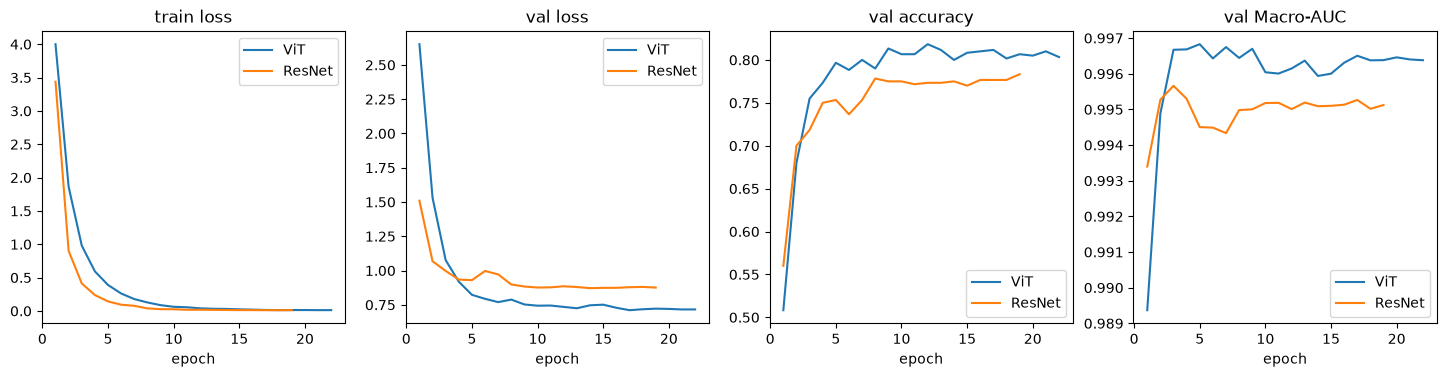

[saved] /cluster/home/m315832001/class/MMIP/week4/Outputs/Q3_training_curves.png


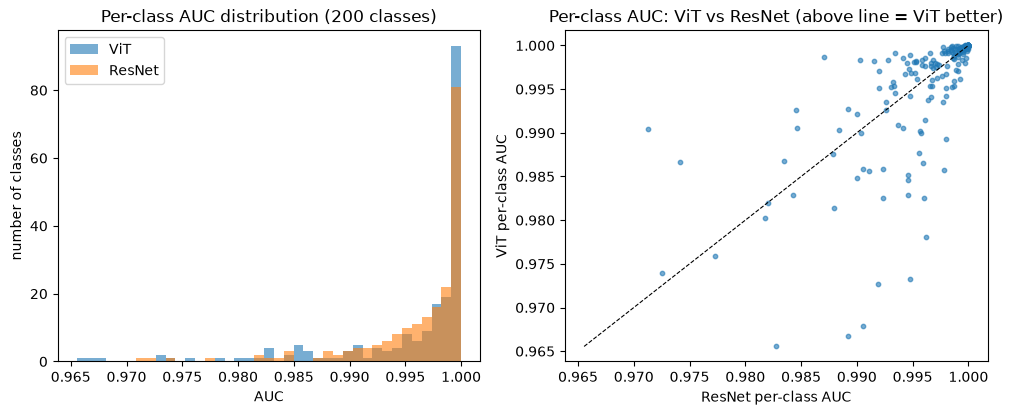

[saved] /cluster/home/m315832001/class/MMIP/week4/Outputs/Q3_auc_comparison.png


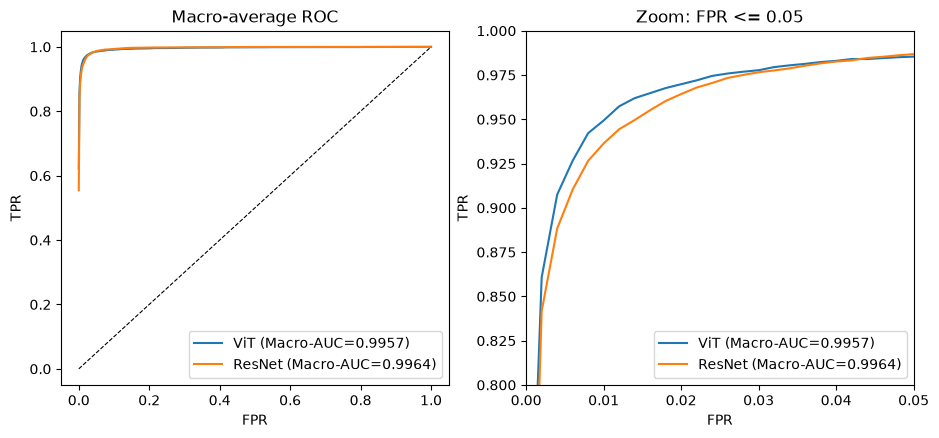

[saved] /cluster/home/m315832001/class/MMIP/week4/Outputs/Q3_roc_curves.png


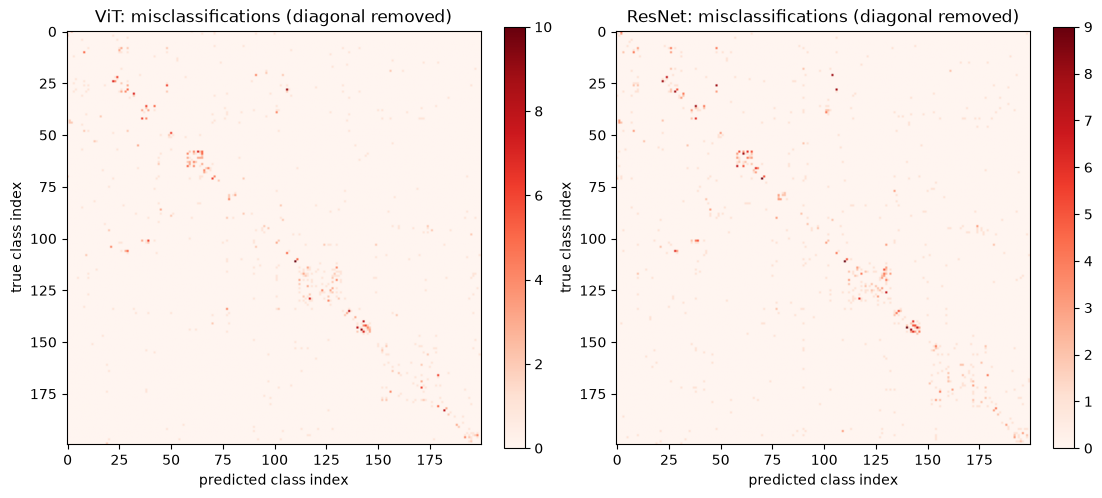

[saved] /cluster/home/m315832001/class/MMIP/week4/Outputs/Q3_confusion_matrix.png


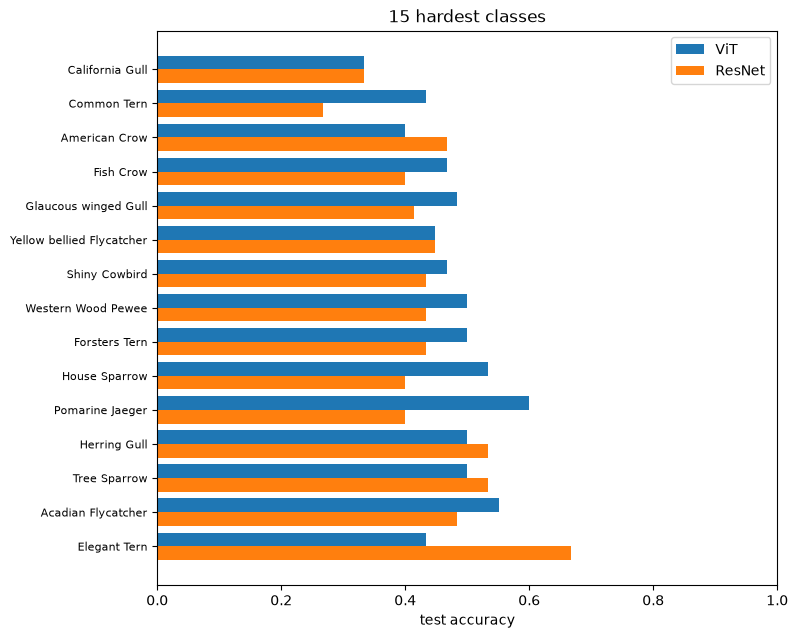

[saved] /cluster/home/m315832001/class/MMIP/week4/Outputs/Q3_worst_classes.png


,Accuracy,Top5_Acc,Macro_F1,Macro_AUC,Params(M),Epochs_run,Best_epoch,Train_time_s
ViT,0.8217,0.9563,0.8222,0.9957,85.9525,22.0,17.0,365.0795
ResNet,0.7970,0.9505,0.7980,0.9964,23.9178,19.0,14.0,142.6978


,AUC_ViT,Acc_ViT,AUC_ResNet,Acc_ResNet
count,200.0000,200.0000,200.0000,200.0000
mean,0.9957,0.8232,0.9964,0.7992
std,0.0068,0.1520,0.0051,0.1604
min,0.9655,0.3333,0.9713,0.2667
25%,0.9953,0.7327,0.9949,0.7181
50%,0.9988,0.8667,0.9985,0.8333
75%,0.9998,0.9333,0.9997,0.9333
max,1.0000,1.0000,1.0000,1.0000


,AUC_ViT,Acc_ViT,AUC_ResNet,Acc_ResNet,mean_acc
California Gull,0.992,0.333,0.990,0.333,0.333
Common Tern,0.988,0.433,0.988,0.267,0.350
American Crow,0.991,0.400,0.994,0.467,0.433
Fish Crow,0.993,0.467,0.993,0.400,0.433
Glaucous winged Gull,0.983,0.483,0.996,0.414,0.448
Yellow bellied Flycatcher,0.976,0.448,0.977,0.448,0.448
Shiny Cowbird,0.991,0.467,0.985,0.433,0.450
Western Wood Pewee,0.993,0.500,0.989,0.433,0.467
Forsters Tern,0.990,0.500,0.996,0.433,0.467
House Sparrow,0.990,0.533,0.990,0.400,0.467


In [6]:
res3, per_cls3, probs3, y3 = q3.evaluate_and_plot(ctx3, vit_res, resnet_res)
display(res3.round(4))

# 每類別表：200 列太長，改看統計摘要與最難的 10 類
display(per_cls3.describe().round(4))
display(per_cls3.assign(mean_acc=per_cls3[['Acc_ViT', 'Acc_ResNet']].mean(axis=1))
        .sort_values('mean_acc').head(10).round(3))

#### 3-3 結果分析

| 模型 | Top-1 Acc | Top-5 Acc | Macro-F1 | Macro-AUC | 參數量 (M) | 最佳 / 實際 Epoch | 訓練時間 (s) |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **ViT-B/16** | 82.17% | 95.63% | 0.8222 | 0.9957 | 85.95 | 17 / 22 | 365.08 |
| **ResNet-50** | 79.70% | 95.05% | 0.7980 | 0.9964 | 23.92 | 14 / 19 | 142.70 |

ViT-B/16 在 Top-1 Accuracy、Top-5 Accuracy 與 Macro-F1 三項指標上均優於 ResNet-50。  
兩個模型的 Top-5 Accuracy 均達到 95% 以上，代表正確鳥種大多能進入模型預測機率最高的五個類別中。  
然Top-1 與 Top-5 之間仍有約 13 至 14 %的差距，顯示模型雖然通常能辨識出正確類別的候選範圍，但在外觀相近的鳥種之間，仍可能分錯。

ViT 的參數量約為 ResNet-50 的 3.59 倍，ViT 的訓練時間約為 ResNet-50 的 2.56 倍。
儘管 ViT 在本次實驗中取得較高的 Top-1 Accuracy 與 Macro-F1，其效能提升也伴隨較高的計算成本。若應用情境重視分類準確率，可以優先考慮 ViT；若更重視訓練效率、模型大小或部署資源，ResNet-50 仍具有實用價值。

### 3-4 影像分類推論

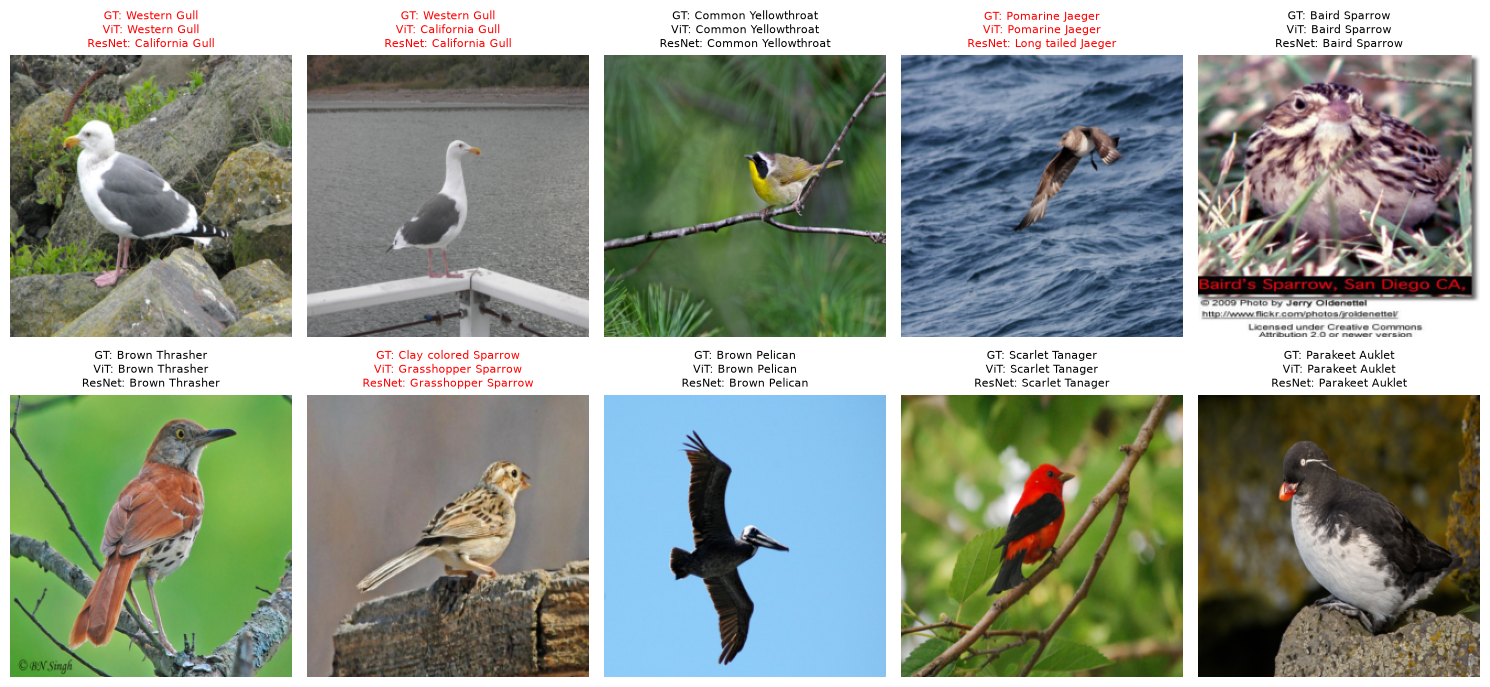

[saved] /cluster/home/m315832001/class/MMIP/week4/Outputs/Q3_prediction_examples.png


In [7]:
q3.show_predictions(ctx3, probs3, n=10)

## Quiz 4：Image Captioning (Flickr8k)
**注意：請自行在 `.env` 輸入 `GEMINI_API_KEY`**

比較兩種方法（以 batch size = 1 計時 PIL 圖片 → 文字的端到端時間）。

| 項目 | 方法 A：CNN + LSTM（自訓練） | 方法 B：BLIP（預訓練） |
|---|---|---|
| 視覺編碼 | ResNet-50（ImageNet，凍結）取 2,048 維池化特徵，預先抽取並快取 | BLIP 內建 ViT 編碼器 |
| 解碼器 | LSTM（embedding 128、hidden 256、dropout 0.5）；圖像特徵同時用於初始化隱藏狀態，並在每個時間步串接輸入 | BLIP 文字解碼器 |
| 詞表 | 訓練集詞頻 ≥ 5，共 2,539 詞 | 內建 tokenizer |
| 訓練 | CrossEntropy、Adam lr = 1e-3、batch 128、early stopping（patience 3，上限 25 epochs，於第 21 個 epoch 停止） | 不訓練，直接零樣本推論（`Salesforce/blip-image-captioning-base`） |
| 解碼 | 貪婪解碼，最長 30 詞 | beam search（`num_beams=3`），最多 30 個新 token |
| 評估集 | 從測試集以固定種子 42 隨機抽 100 張（N_EVAL=100），兩方法共用同一批圖，每張 5 句參考描述  |
| 指標 | BLEU-4（sacrebleu，多參考）、BERTScore F1（roberta-large，多參考取最高，未做 baseline 縮放）、延遲、Gemini 判斷（符合與否 + 1–5 分）  |

**Gemini 評判**：模型 `gemini-3.5-flash-lite`，輸入圖片與描述，要求以 JSON 回傳 `match`、`score`（1–5）與 `reason`；`N_JUDGE = 10`，每個方法判斷 10 張。

In [ ]:
# ---- 設定 ----
N_EVAL = 1000    # 兩種方法共同評估的測試圖張數
N_JUDGE = 10     # 送 Gemini 評判的張數，受限於免費版本估總共能判斷20張左右（每個方法 N_JUDGE 次呼叫，共 2×N_JUDGE 次）
GEMINI_MODEL = 'gemini-3.5-flash-lite'   # 若不可用，請改成目前可用的 Gemini 模型
GEMINI_SLEEP = 4                    # 每次呼叫後等待秒數（避免超過速率限制）


import os
from pathlib import Path
from dotenv import load_dotenv

# 從目前 Notebook 的工作目錄尋找 .env
load_dotenv(dotenv_path=Path.cwd() / ".env")
GEMINI_API_KEY = os.getenv("GEMINI_API_KEY")
#print(GEMINI_API_KEY)
if not GEMINI_API_KEY:
    raise ValueError("找不到 GEMINI_API_KEY，請檢查 .env 路徑與內容。")

ctx4 = q4.load_context(paths)
q4.setup_gemini(ctx4, GEMINI_API_KEY, GEMINI_MODEL, GEMINI_SLEEP)

### 4-1 抽取 ResNet-50 特徵（快取）

In [15]:
q4.extract_features(ctx4)

### 4-2 訓練 CNN+LSTM 解碼器（方法 A）

caption vocab: 2539
ep1 train_loss=4.6488 val_loss=3.8560
ep2 train_loss=3.7936 val_loss=3.4590
ep3 train_loss=3.4846 val_loss=3.2513
ep4 train_loss=3.2980 val_loss=3.1272
ep5 train_loss=3.1653 val_loss=3.0458
ep6 train_loss=3.0620 val_loss=2.9881
ep7 train_loss=2.9763 val_loss=2.9430
ep8 train_loss=2.9062 val_loss=2.9172
ep9 train_loss=2.8472 val_loss=2.8939
ep10 train_loss=2.7928 val_loss=2.8740
ep11 train_loss=2.7459 val_loss=2.8670
ep12 train_loss=2.7003 val_loss=2.8528
ep13 train_loss=2.6603 val_loss=2.8497
ep14 train_loss=2.6271 val_loss=2.8380
ep15 train_loss=2.5906 val_loss=2.8357
ep16 train_loss=2.5598 val_loss=2.8379
ep17 train_loss=2.5329 val_loss=2.8379
ep18 train_loss=2.5051 val_loss=2.8309
ep19 train_loss=2.4812 val_loss=2.8328
ep20 train_loss=2.4546 val_loss=2.8346
ep21 train_loss=2.4315 val_loss=2.8354
early stop
[saved] /cluster/home/m315832001/class/MMIP/week4/Outputs/q4_cnn_lstm.pt


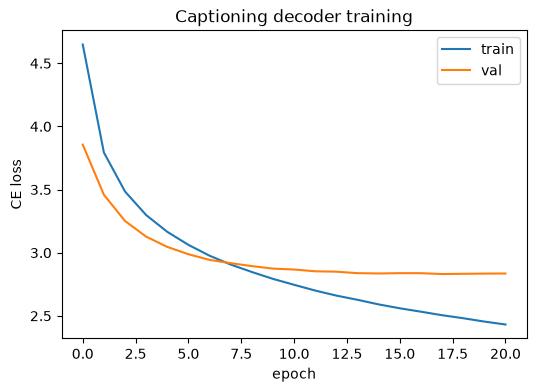

[saved] /cluster/home/m315832001/class/MMIP/week4/Outputs/Q4_training_curve.png


In [16]:
q4.build_vocab(ctx4, min_freq=5)
cap_hist = q4.train_decoder(ctx4, epochs=25, patience=3)

### 4-3 兩種方法產生描述

In [17]:
q4.load_blip(ctx4)
q4.build_eval_set(ctx4, n_eval=N_EVAL)
q4.generate_all(ctx4)

Loading weights: 100%|██████████| 473/473 [00:00<00:00, 41567.79it/s]


running A_CNN+LSTM
  avg latency 0.009s | empty captions: 0 | e.g. a man is jumping over a brown dog
running B_BLIP
  avg latency 0.081s | empty captions: 0 | e.g. a man is throwing a ball in the yard


### 4-4 BLEU / BERTScore

In [12]:
metric_df = q4.text_metrics(ctx4)
metric_df.round(4)

Loading weights: 100%|██████████| 389/389 [00:00<00:00, 17342.52it/s]
[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.bias              | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


A_CNN+LSTM {'BLEU-4': 18.860486264678777, 'BERTScore_F1': 0.9213966131210327, 'Latency_s': 0.009155569900758564, 'Empty_captions': 0}


Loading weights: 100%|██████████| 389/389 [00:00<00:00, 15842.32it/s]
[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.bias              | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


B_BLIP {'BLEU-4': 16.32277606741927, 'BERTScore_F1': 0.9425004720687866, 'Latency_s': 0.07775135880801827, 'Empty_captions': 0}


,BLEU-4,BERTScore_F1,Latency_s,Empty_captions
A_CNN+LSTM,18.8605,0.9214,0.0092,0.0
B_BLIP,16.3228,0.9425,0.0778,0.0


### 4-5 Gemini 判斷描述是否符合影像

In [ ]:
if ctx4.get('has_gemini'):
    judge_summary = q4.judge_all(ctx4, n_judge=N_JUDGE)
    metric_df = (metric_df.drop(columns=[c for c in metric_df.columns if c.startswith('Gemini_')])
                          .join(judge_summary))
    display(judge_summary)
    display(ctx4['judge_df'].groupby('method').head(5))

judged A_CNN+LSTM
judged B_BLIP


,Gemini_match_rate,Gemini_mean_score
method,,
A_CNN+LSTM,0.1,1.9
B_BLIP,0.8,4.3


,method,idx,caption,match,score,reason
0,A_CNN+LSTM,0,a man is jumping over a brown dog,False,1,The image shows a man running through a dusty ...
1,A_CNN+LSTM,1,a little boy in a blue shirt is playing in a p...,False,1,The image shows a little girl in a swimsuit pl...
2,A_CNN+LSTM,2,a man in a red shirt is walking down a street,False,1,There is no man in a red shirt walking down th...
3,A_CNN+LSTM,3,two children are playing in a bed,False,2,"The children are playing in a living room, not..."
4,A_CNN+LSTM,4,a girl in a pink dress is standing on a beach,False,1,The image shows a boy sandboarding down a dune...
10,B_BLIP,0,a man is throwing a ball in the yard,False,1,The man is running through sand or dust in a y...
11,B_BLIP,1,a child playing in a water park with an inflat...,False,2,"The child is playing in a water park, but ther..."
12,B_BLIP,2,a group of people walking down a street,True,5,The image clearly shows a group of people walk...
13,B_BLIP,3,a little boy playing with toys in a living room,True,5,The caption accurately describes a little boy ...
14,B_BLIP,4,two people are playing in the sand dunes,True,5,The image shows two people enjoying activities...


### 4-6 實驗結果整理

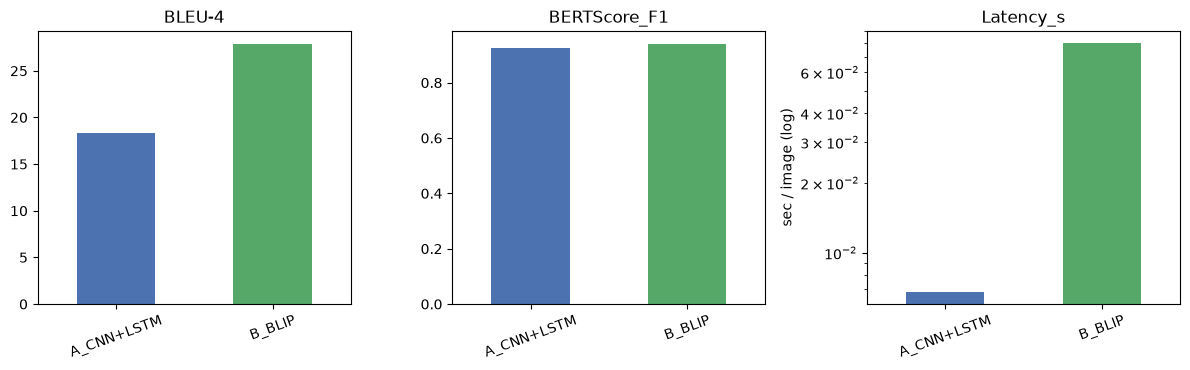

[saved] /cluster/home/m315832001/class/MMIP/week4/Outputs/Q4_method_comparison.png


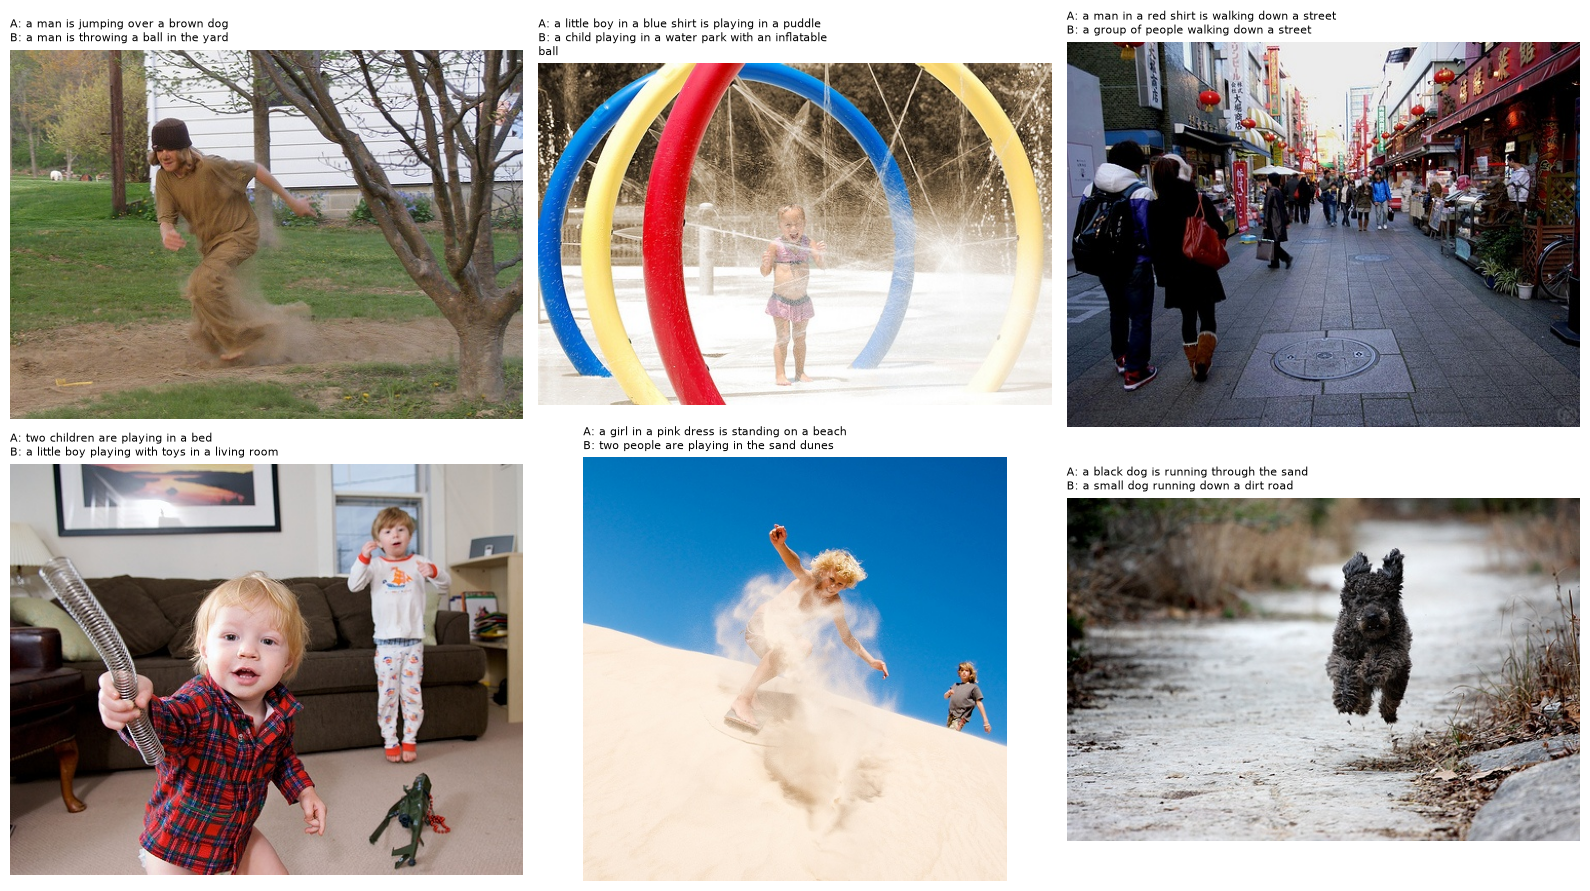

[saved] /cluster/home/m315832001/class/MMIP/week4/Outputs/Q4_caption_examples.png


,BLEU-4,BERTScore_F1,Latency_s,Empty_captions
A_CNN+LSTM,18.3179,0.9241,0.0068,0.0
B_BLIP,27.8725,0.9398,0.0798,0.0


In [10]:
final_df = q4.summarize_and_plot(ctx4, metric_df, n_judge=N_JUDGE)
display(final_df)

#### 4-6 結果分析
| 方法 | BLEU-4 | BERTScore F1 | 平均延遲 | Gemini 符合率 | Gemini 平均分 |
|---|---|---|---|---|---|
| A：CNN+LSTM | 19.78 | 0.9217 | **0.007 s** | 0.1（1/10） | 1.9 |
| B：BLIP | **27.47** | **0.9373** | 0.079 s | **0.8（8/10）** | **4.3** |

- **BLIP 在三個品質指標上都較佳**：BLEU-4 高約 7.7、BERTScore 高 0.016、Gemini 符合率明顯較高。BERTScore 因為未做 baseline 縮放，數值都被壓縮在 0.92–0.94。

- **自訓練模型的典型問題**：它能抓到場景的大類（人、街道、沙灘、遊戲），但常說錯細節。例如第 0 張圖，A 說「a man is jumping over a brown dog」，Gemini 認為圖片是一個人在塵土中奔跑，判為不符合；第 2 張圖「a man in a red shirt walking down a street」，Gemini 指出圖中並沒有穿紅衣的男子。BLIP 在同批圖中也有判錯（例如第 0、1 張被判不符合），但整體正確率高得多。

- **訓練收斂**：解碼器 val loss 在第 18 個 epoch 達到最低（2.8309），之後 train loss 持續下降而 val loss 回升，屬於 Flickr8k 資料量小（6000 張）造成的過擬合，early stopping 在第 21 個 epoch 停止

- **Gemini 判斷的樣本數極小**：受限於API用量每個方法只判斷超過 10 張會爆，所以只能看出 BLIP正確率應會遠高於 BERTscore

## 結論

**Quiz 2（RNN vs LSTM，Yelp 三類）**  
LSTM 在所有指標上都明顯優於 RNN：Accuracy 0.741 對 0.661，Macro-F1 0.742 對 0.654，Macro-AUC 0.896 對 0.831，嚴重錯誤率也降到不到一半，而且參數量只多約 4%、收斂更快更穩。差距主要來自最模糊的 neutral 類別（recall 0.66 對 0.46）。序列長度實驗中，兩個模型都隨長度增加而進步，LSTM 在每個長度都領先 8.8–12.6 %，但差距並未隨長度單調擴大，因此不能由本實驗推論「序列越長 RNN 越差」。

**Quiz 3（ViT vs ResNet，CUB-200-2011 二百類）**  
ViT 在 Top-1 Accuracy（0.822 對 0.797）、Top-5 Accuracy（0.956 對 0.951）及 Macro-F1（0.822 對 0.798）上均優於 ResNet，但 Macro-AUC 略低（0.996 對 0.996）。ViT 的參數量約為 ResNet 的 3.6 倍，訓練時間也約為 2.6 倍，顯示分類效能提升伴隨較高成本。部分鳥種的辨識率仍偏低，反映二百類細粒度分類的困難；此外，驗證集每類約僅 3 張圖片，可能影響 Early Stopping 的穩定性。由於僅使用單一隨機種子，兩模型的小幅差距仍需進一步實驗驗證。

**Quiz 4（Image Captioning）**  
預訓練的 BLIP 在品質上全面勝出（BLEU-4 27.5 對 19.8，BERTScore 0.937 對 0.922，Gemini 符合率 8/10 對 1/10），代價是延遲約 11 倍（0.079 s 對 0.007 s）。自訓練的 CNN+LSTM 速度快、模型小，但受限於 Flickr8k 的資料量，常說錯細節。Gemini 判斷的樣本只有每方法 10 張，結論僅具方向性。

In [ ]:
# 儲存輸出
for p in sorted(paths['outputs'].iterdir()):
    print(p.name)